In [1]:
import sys

sys.path.append("..")

import numpy as np
from classes.loader.loader import Loader
from classes.signal import SignalTime
from classes.sample import Sample, SingleSample, SampleTypes
from classes.common import Cables
import matplotlib.pyplot as plt
import scipy
from tqdm.notebook import tqdm
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from scipy.signal import hilbert, butter, sosfilt
import json
# from scipy.io import wavfile


c:\Users\eduar\OneDrive\Documentos\Projetos\Doutorado\project\.venv\lib\site-packages\pydantic\_internal\_fields.py:149: UserWarning: Field "model_server_url" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
c:\Users\eduar\OneDrive\Documentos\Projetos\Doutorado\project\.venv\lib\site-packages\pydantic\_internal\_config.py:321: UserWarning: Valid config keys have changed in V2:
* 'schema_extra' has been renamed to 'json_schema_extra'
  warnings.warn(message, UserWarning)


In [2]:
def bandpass(signal: SignalTime, f0: float, f1: float) -> SignalTime:
    #sos = butter(N=N, Wn=[f0, f1], btype="bandpass", fs=1 / signal.ts, output="sos")
    #filtered = sosfilt(sos, signal.signal)
    #return SignalTime(signal=filtered, ts=signal.ts, id=signal.id)

    x = np.fft.fft(signal.signal)
    f = np.fft.fftfreq(len(signal), signal.ts)
    idx = (np.abs(f) > f0) & (np.abs(f) < f1)
    new_x = x * 0
    new_x[idx] = x[idx]
    new_s = np.fft.ifft(new_x)
    return SignalTime(np.real(new_s), signal.ts, None)

def get_analytic(signal: SignalTime) -> SignalTime:
    h = hilbert(np.array(signal.signal))
    return SignalTime(signal=list(h), ts=signal.ts, id=signal.id)

In [3]:
# load the signal

filename = "2022_11_19_08_34"

loader = Loader(r"..\raw\sequence_1")
sample = loader.load_one(f"{filename}.json")
sample.convert_to_time()

In [410]:
from scipy.signal import stft, hilbert, find_peaks, welch, windows

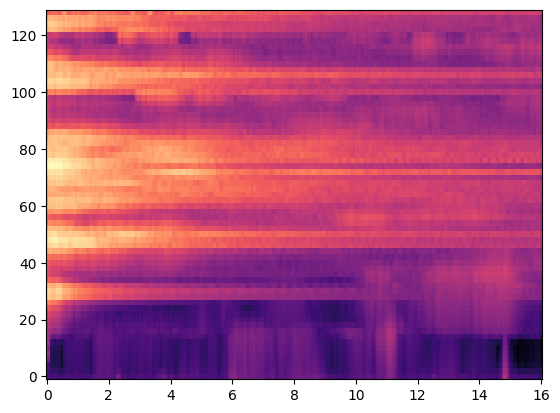

In [438]:
signal = sample.sample_c4.z
t, x = signal.get()
ts = signal.ts
fs = 1 / ts

f, t, S = stft(x, fs, window="hann", nperseg=128, noverlap=120)
Sa = abs(S)

# xa = hilbert(Sa, axis=1)
# xam = abs(xa)
# fam_s, xam_s = welch(xam, nperseg=512, noverlap=500, axis=1, fs=1/(t[1]-t[0]))

fam_s, xam_s = welch(abs(Sa), nperseg=512, axis=1, fs=1/(t[1]-t[0]))
# xam_s = np.fft.rfft(abs(Sa)**2, axis=1)[:,1:]
# fam_s = np.fft.rfftfreq(Sa.shape[1], t[1]-t[0])[1:]

plt.pcolormesh(fam_s, f, 20*np.log10(abs(xam_s)), cmap="magma")

In [ ]:
# tensions raw
headers_LMS = pd.read_table(PATH_TO_RAW_SAMPLE, skiprows=8, nrows=1, sep="  ", engine="python")
headers_LMS = list(headers_LMS)
df_LMS = pd.read_table(PATH_TO_RAW_SAMPLE, skiprows=9, sep="    ", engine="python", header=None)
df_LMS.columns = headers_LMS
df_tensions = df_LMS[["S1_T2[N]", "S2_T2[N]", "S3_T2[N]", "S4_T4[N]"]]

# tensions signals
tensions = []
for i, s in enumerate(sample):
    ts = s.x.ts
    tensions.append(SignalTime(signal=list(df_tensions.to_numpy()[:,i]), ts=ts, id=s.x.id))

data = {}
for c in range(4):
    data[f"tensions{c}"] = tensions[c].signal
    t = np.arange(0, len(sample[c].x.signal)*ts, ts)
df_tensions = pd.DataFrame(data, index=t)

In [ ]:
px.line(df_tensions)

In [ ]:
spectrums = []
times = []
envelopes = []
spectrums_demod = []
spectrums_env = []

for c in range(4):
    print(f"cable {c}: tension = {sample[c].tension}")
    ts = sample[c].x.ts
    t = np.arange(0, len(sample[c].x.signal)*ts, ts)

    f1 = 0.1
    f2 = 10

    signal_x = bandpass(sample[c].x, f1, f2)
    signal_y = bandpass(sample[c].y, f1, f2)
    signal_z = bandpass(sample[c].z, f1, f2)

    #signal_x_env, signal_x_demod = hilbert_abs(signal_x)
    #signal_y_env, signal_y_demod = hilbert_abs(signal_y)
    #signal_z_env, signal_z_demod = hilbert_abs(signal_z)

    asignal_x = get_analytic(signal_x)
    asignal_y = get_analytic(signal_y)
    asignal_z = get_analytic(signal_z)

    abs_signal_x = SignalTime(signal=np.abs(asignal_x.signal), ts=asignal_x.ts, id=asignal_x.id)
    abs_signal_y = SignalTime(signal=np.abs(asignal_y.signal), ts=asignal_y.ts, id=asignal_y.id)
    abs_signal_z = SignalTime(signal=np.abs(asignal_z.signal), ts=asignal_z.ts, id=asignal_z.id)

    sq_signal_x = SignalTime(signal=np.real(np.array(asignal_x.signal)*np.conj(np.array(asignal_x.signal))), ts=asignal_x.ts, id=asignal_x.id)
    sq_signal_y = SignalTime(signal=np.real(np.array(asignal_y.signal)*np.conj(np.array(asignal_y.signal))), ts=asignal_y.ts, id=asignal_y.id)
    sq_signal_z = SignalTime(signal=np.real(np.array(asignal_z.signal)*np.conj(np.array(asignal_z.signal))), ts=asignal_z.ts, id=asignal_z.id)

    unit_signal_x = SignalTime(signal=np.array(signal_x.signal)/np.array(abs_signal_x.signal), ts=asignal_x.ts, id=asignal_x.id)
    unit_signal_y = SignalTime(signal=np.array(signal_y.signal)/np.array(abs_signal_y.signal), ts=asignal_y.ts, id=asignal_y.id)
    unit_signal_z = SignalTime(signal=np.array(signal_z.signal)/np.array(abs_signal_z.signal), ts=asignal_z.ts, id=asignal_z.id)

    df_time = pd.DataFrame({
        f"x{c}": sample[c].x.signal,
        f"y{c}": sample[c].y.signal,
        f"z{c}": sample[c].z.signal,
    }, index=t)
    times.append(df_time)
    
    df_env = pd.DataFrame({
        f"x{c}": abs_signal_x.signal,
        f"y{c}": abs_signal_y.signal,
        f"z{c}": abs_signal_z.signal,
    }, index=t)
    envelopes.append(df_env)

    sx = signal_x.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    sy = signal_y.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    sz = signal_z.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    df = pd.DataFrame({
        f"x{c}": sx.magnitudes,
        f"y{c}": sy.magnitudes,
        f"z{c}": sz.magnitudes
    }, index=sx.frequencies)
    spectrums.append(df)

    sx = unit_signal_x.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    sy = unit_signal_y.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    sz = unit_signal_z.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    df_spectrums_demod = pd.DataFrame({
        f"x{c}": sx.magnitudes,
        f"y{c}": sy.magnitudes,
        f"z{c}": sz.magnitudes
    }, index=sx.frequencies)
    spectrums_demod.append(df_spectrums_demod)

    sx = sq_signal_x.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    sy = sq_signal_y.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    sz = sq_signal_z.to_spectrum(window="hamming", nperseg=2048, poverlap=0.5)
    df_spectrums_env = pd.DataFrame({
        f"x{c}": sx.magnitudes,
        f"y{c}": sy.magnitudes,
        f"z{c}": sz.magnitudes
    }, index=sx.frequencies)
    spectrums_env.append(df_spectrums_env)

spectrums = pd.concat(spectrums, axis=1)
times = pd.concat(times, axis=1)
envelopes = pd.concat(envelopes, axis=1)
spectrums_demod = pd.concat(spectrums_demod, axis=1)
spectrums_env = pd.concat(spectrums_env, axis=1)

In [ ]:
px.line(times)

In [ ]:
px.line(envelopes)

In [ ]:
px.line(spectrums_env)

In [ ]:
px.line(spectrums)

In [ ]:
px.line(spectrums_demod)

# Cyclostationary

In [ ]:
# def pa(x, a):
#     N = len(x)
#     dt = 0.00390625
#     t = np.arange(0, N*dt, dt)
#     ep = np.exp(1j*2*np.pi*a*t)
#     en = np.exp(1j*(-2)*np.pi*a*t)
#     p0a = np.mean(x * en)
#     return p0a * ep

In [ ]:
def pa(signal: SignalTime, a_hz: float) -> SignalTime:

    n = np.arange(len(signal))
    e = np.exp(1j*2*np.pi*a_hz*n*signal.ts)
    e_ = np.exp(-1j*2*np.pi*a_hz*n*signal.ts)
    dft_a = np.mean(np.array(signal.signal) * e_)
    return SignalTime(dft_a * e, ts=signal.ts, id=None)

In [ ]:
def p(signal: SignalTime, a_list: list[float]) -> SignalTime:
    x_full = np.zeros(len(signal))
    for a in a_list:
        sa = pa(signal, a)
        _, x = sa.get()
        x_full = x_full + np.array(x)
    return SignalTime(x_full, ts=signal.ts, id=None)


In [ ]:
signal = sample[1].y

a = np.arange(0, 30, 0.5)
power_signal = SignalTime(signal=np.abs(np.array(signal.signal))**2, ts=signal.ts, id=None)
power_signal_a = p(power_signal, a)

In [ ]:
fig = go.Figure()
t, x = signal.get()
fig.add_trace(go.Scatter(x=t, y=x, name="signal"))

t, x = power_signal_a.get()
fig.add_trace(go.Scatter(x=t, y=np.abs(x), name="power"))

fig.show()

In [ ]:
def get_inst_freq(signal: SignalTime):
    instantaneous_phase = np.unwrap(np.angle(signal.signal))
    instantaneous_frequency = (np.diff(instantaneous_phase) /
                            (2.0*np.pi) / signal.ts)
    return SignalTime(instantaneous_frequency, signal.ts, None)

In [ ]:
signal = sample[1].y

signal_bp = bandpass(signal, 3.5, 7)
signal_an = get_analytic(signal_bp)
signal_an_abs = SignalTime(np.abs(signal_an.signal), signal.ts, None)
signal_if = get_inst_freq(signal_an)
signal_norm = SignalTime(signal_bp.signal / signal_an_abs.signal, signal.ts, None)

signal_dft = signal.to_spectrum("hamming", 512, 0.5)
signal_bp_dft = signal_bp.to_spectrum("hamming", 512, 0.5)
signal_an_dft = signal_an_abs.to_spectrum("hamming", 512, 0.5)
signal_norm_dft = signal_norm.to_spectrum("hamming", 512, 0.5)

fig = go.Figure()
fig.add_trace(go.Scatter(x=signal_bp.get()[0], y=signal_bp.get()[1], name="bandpass"))
fig.add_trace(go.Scatter(x=signal_an_abs.get()[0], y=signal_an_abs.get()[1]))
fig.show()

fig = go.Figure()
fig.add_trace(go.Scatter(x=signal_dft.get()[0], y=signal_dft.get()[1], name="original"))
fig.add_trace(go.Scatter(x=signal_bp_dft.get()[0], y=signal_bp_dft.get()[1], name="bp"))
fig.add_trace(go.Scatter(x=signal_norm_dft.get()[0], y=signal_norm_dft.get()[1], name="norm"))
fig.show()

fig = px.line(x=signal_an_dft.get()[0], y=signal_an_dft.get()[1])
fig.show()

fig = px.line(x=signal_if.get()[0], y=signal_if.get()[1])
fig.show()

# fig = px.line(x=signal_norm.get()[0], y=signal_norm.get()[1])
# fig.show()


# Whole dataset view

In [ ]:
from classes.feature.feature_extractors import (
    PSDFeatureExtractor,
    EnvelopePSDFeatureExtractor,
    UnitMagPSDFeatureExtractor,
)

In [ ]:
PATH_TO_TRAIN_DATASET = r"../raw/sequence_2/"

In [ ]:
psd_transformer = EnvelopePSDFeatureExtractor(
    f_min=0.1, f_max=127, nperseg=1024, poverlap=0.5, normalize=False
)
loader = Loader(PATH_TO_TRAIN_DATASET, psd_transformer)
dfs_per_cable = loader.load_from_folder()

In [ ]:
cable = Cables.C1

xx = np.vstack(dfs_per_cable[cable].features.to_list())
fs = 256
df = (fs/2) / xx.shape[2]
f = np.linspace(df, fs/2, xx.shape[2])

fig = px.imshow(
    np.log(xx[:, 1, :]), #np.log(xx[:, 1, :]),
    color_continuous_scale="RdBu_r",
    origin="lower",
    aspect="auto",
    y=dfs_per_cable[cable].tension,
    x=f
)
fig.update_layout(yaxis_title="Tension (N)", xaxis_title="Frequency (Hz)")
fig.show()

fig = px.imshow(
    np.log(xx[:, 2, :]), # np.log(xx[:, 2, :]),
    color_continuous_scale="RdBu_r",
    origin="lower",
    aspect="auto",
    y=dfs_per_cable[cable].tension,
    x=f
)
fig.update_layout(yaxis_title="Tension (N)", xaxis_title="Frequency (Hz)")
fig.show()


# Simulation

In [ ]:
import scipy.io
PATH_TO_SIMULATION_DATASET = r"../raw/simulation/"
mat = scipy.io.loadmat(PATH_TO_SIMULATION_DATASET + 'Cabo1_1.mat')

In [ ]:
sample = SingleSample(
    x = SignalTime(mat["X"].reshape(-1), ts=1/100, id=None),
    y = SignalTime(mat["Y"].reshape(-1), ts=1/100, id=None),
    z = SignalTime(mat["Z"].reshape(-1), ts=1/100, id=None),
    tension=0.0,
    type=SampleTypes.TIME
)

In [ ]:
df = sample.to_pandas()

In [ ]:
px.line(df)